# Практическая работа №4. Регрессионный анализ

**Предметная область:** Мониторинг безопасности СУБД PostgreSQL  
**Тип задачи:** Регрессия — прогнозирование времени выполнения SQL-запроса  
**Источник данных:** Набор данных логов PostgreSQL-сервера  

Цель: построить и сравнить линейные, нелинейные и квантильные регрессионные модели для предсказания `execution_time_ms` на основе характеристик серверной инфраструктуры.

---

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, QuantileRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

print('Библиотеки импортированы.')

Библиотеки импортированы.


## Подготовка данных (по результатам ПР1)

In [3]:
df = pd.read_csv("../sql_dataset_loreal.csv")
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek

# Регрессия строится только на нормальных запросах
df_reg = df[df['label'] == 'normal'].copy()
print(f'Подвыборка нормальных запросов: {df_reg.shape[0]} наблюдений')

# Удаление нерелевантных признаков
cols_to_drop = ['ip_address', 'sql_query', 'timezone', 'is_anomaly', 'timestamp', 'city', 'label']
df_work = df_reg.drop(columns=cols_to_drop)

# Целевая переменная
y = df_work['execution_time_ms'].values
X_raw = df_work.drop(columns=['execution_time_ms'])

# One-Hot кодирование категориальных признаков
X_encoded = pd.get_dummies(X_raw, columns=['country', 'query_type'], drop_first=True).astype(float)

# Инженерные признаки
X_encoded['cpu_x_conn'] = df_reg['cpu_load_pct'].values * df_reg['active_connections'].values
X_encoded['log_rows'] = np.log1p(df_reg['rows_affected'].values)

num_features = ['cpu_load_pct', 'ram_usage_mb', 'active_connections',
                'rows_affected', 'hour', 'day_of_week', 'cpu_x_conn', 'log_rows']

scaler = StandardScaler()
X_scaled = X_encoded.copy()
X_scaled[num_features] = scaler.fit_transform(X_encoded[num_features])

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled.values, y, test_size=0.2, random_state=42
)

print(f'Обучающая выборка: {X_train.shape}')
print(f'Тестовая выборка:  {X_test.shape}')
print(f'Целевая переменная — среднее: {y.mean():.2f} мс, ст.откл.: {y.std():.2f} мс')

Подвыборка нормальных запросов: 9624 наблюдений
Обучающая выборка: (7699, 20)
Тестовая выборка:  (1925, 20)
Целевая переменная — среднее: 360.93 мс, ст.откл.: 371.24 мс


---
## 4.1. Построение линейной регрессии (простая и множественная)

### 4.1.1. Простая линейная регрессия

Модель: $\hat{y} = \beta_0 + \beta_1 x$

Оценки МНК:
$$\hat{\beta}_1 = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^n (x_i - \bar{x})^2}, \quad \hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$$

Предположения классической линейной регрессии (CLRM):
- **Линейность** — зависимость $y$ от $x$ линейна
- **Независимость ошибок** — $\varepsilon_i$ некоррелированы
- **Гомоскедастичность** — $\mathrm{Var}(\varepsilon_i) = \sigma^2 = \mathrm{const}$
- **Нормальность** — $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$

Уравнение: ŷ = 367.18 + (-0.1449) · cpu_load_pct
R²   = 0.0000
RMSE = 371.23 мс


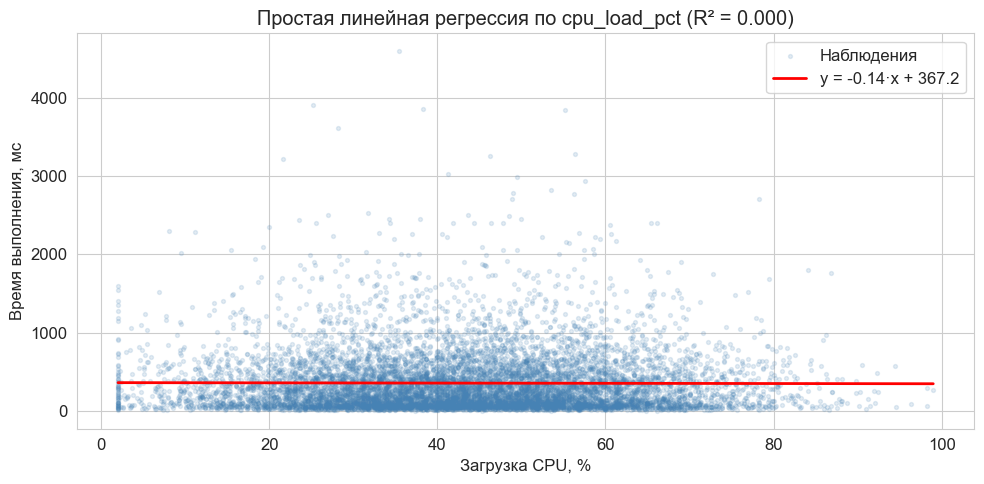

In [4]:
# Простая линейная регрессия: предиктор — cpu_load_pct
x_simple = df_reg['cpu_load_pct'].values.reshape(-1, 1)
y_simple = df_reg['execution_time_ms'].values

slr = LinearRegression()
slr.fit(x_simple, y_simple)
y_slr_pred = slr.predict(x_simple)

r2_slr = r2_score(y_simple, y_slr_pred)
rmse_slr = np.sqrt(mean_squared_error(y_simple, y_slr_pred))

print(f'Уравнение: ŷ = {slr.intercept_:.2f} + ({slr.coef_[0]:.4f}) · cpu_load_pct')
print(f'R²   = {r2_slr:.4f}')
print(f'RMSE = {rmse_slr:.2f} мс')

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df_reg['cpu_load_pct'], y_simple, alpha=0.15, s=8,
           color='steelblue', label='Наблюдения')
x_line = np.linspace(df_reg['cpu_load_pct'].min(), df_reg['cpu_load_pct'].max(), 200)
ax.plot(x_line, slr.intercept_ + slr.coef_[0] * x_line,
        color='red', linewidth=2,
        label=f'y = {slr.coef_[0]:.2f}·x + {slr.intercept_:.1f}')
ax.set_xlabel('Загрузка CPU, %')
ax.set_ylabel('Время выполнения, мс')
ax.set_title(f'Простая линейная регрессия по cpu_load_pct (R² = {r2_slr:.3f})')
ax.legend()
plt.tight_layout()
plt.show()

### 4.1.2. Множественная линейная регрессия

Модель: $\hat{y} = \beta_0 + \sum_{j=1}^p \beta_j x_j$

Матричная форма МНК: $\hat{\boldsymbol{\beta}} = (X^\top X)^{-1} X^\top \mathbf{y}$

Для оценки относительной важности признаков используются **стандартизованные коэффициенты** — они показывают изменение отклика в стандартных отклонениях при изменении предиктора на 1 ст.откл. при фиксированных остальных.

Множественная линейная регрессия — метрики на тесте:
  R²            = 0.4442
  R² (скорр.)   = 0.4384
  RMSE          = 274.65 мс
  MAE           = 171.64 мс


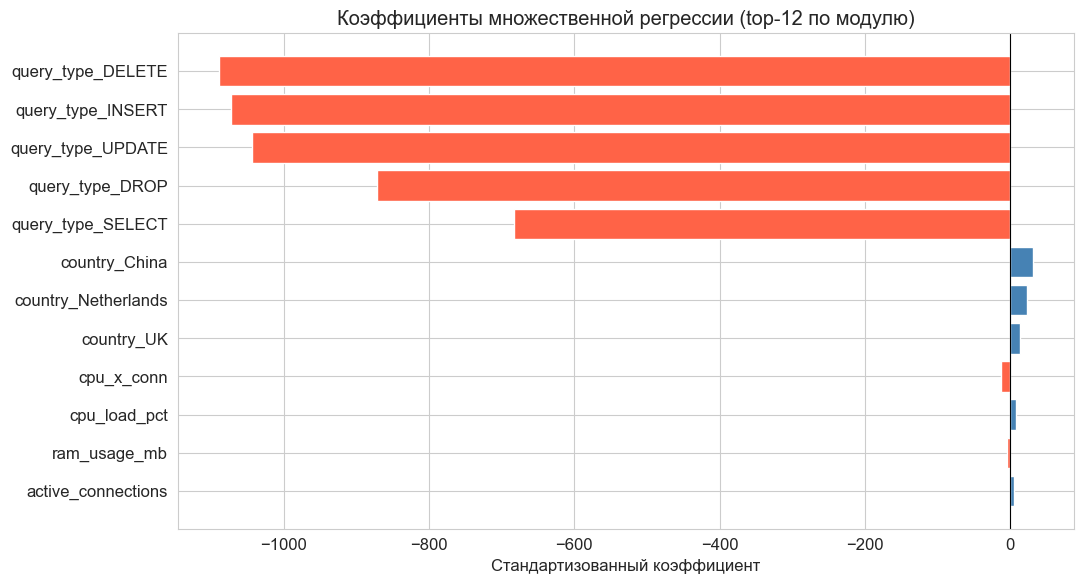

In [5]:
# Множественная линейная регрессия
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_mlr_pred = mlr.predict(X_test)

r2_mlr = r2_score(y_test, y_mlr_pred)
r2_adj_mlr = 1 - (1 - r2_mlr) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
rmse_mlr = np.sqrt(mean_squared_error(y_test, y_mlr_pred))
mae_mlr = mean_absolute_error(y_test, y_mlr_pred)

print('Множественная линейная регрессия — метрики на тесте:')
print(f'  R²            = {r2_mlr:.4f}')
print(f'  R² (скорр.)   = {r2_adj_mlr:.4f}')
print(f'  RMSE          = {rmse_mlr:.2f} мс')
print(f'  MAE           = {mae_mlr:.2f} мс')

# Стандартизованные коэффициенты
feature_names = X_scaled.columns.tolist()
std_coef = pd.Series(mlr.coef_, index=feature_names).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(11, 6))
top12 = std_coef.head(12)
colors = ['tomato' if v < 0 else 'steelblue' for v in top12.values]
ax.barh(top12.index[::-1], top12.values[::-1], color=colors[::-1])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Стандартизованный коэффициент')
ax.set_title('Коэффициенты множественной регрессии (top-12 по модулю)')
plt.tight_layout()
plt.show()

---
## 4.2. Проверка гипотез и анализ остатков

### Гипотезы о значимости коэффициентов

- **H₀**: $\beta_j = 0$ (признак $j$ незначим)
- **H₁**: $\beta_j \neq 0$

Критерий: $t = \hat{\beta}_j / \mathrm{SE}(\hat{\beta}_j)$ следует распределению Стьюдента с $(n - p - 1)$ степенями свободы.

**p-value < 0.05** → отвергаем H₀, признак значим.  
**Доверительный интервал**: $\hat{\beta}_j \pm t_{\alpha/2} \cdot \mathrm{SE}(\hat{\beta}_j)$

In [6]:
# Вычисление t-статистик и p-value вручную через statsmodels-эквивалент
n, p = X_train.shape
X_aug = np.column_stack([np.ones(n), X_train])
beta_hat = np.linalg.lstsq(X_aug, y_train, rcond=None)[0]
y_hat_train = X_aug @ beta_hat
residuals_train = y_train - y_hat_train
sigma2 = np.dot(residuals_train, residuals_train) / (n - p - 1)

XtX_inv = np.linalg.inv(X_aug.T @ X_aug)
se = np.sqrt(sigma2 * np.diag(XtX_inv))
t_stats = beta_hat / se
p_values = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=n - p - 1))
ci_low = beta_hat - stats.t.ppf(0.975, df=n - p - 1) * se
ci_high = beta_hat + stats.t.ppf(0.975, df=n - p - 1) * se

feat_names_aug = ['intercept'] + feature_names
df_coef = pd.DataFrame({
    'coef': beta_hat,
    'se': se,
    't': t_stats,
    'p_value': p_values,
    'CI_low': ci_low,
    'CI_high': ci_high
}, index=feat_names_aug)

sig = df_coef[df_coef['p_value'] < 0.05]
print(f'Значимые коэффициенты (p < 0.05): {len(sig) - 1} из {p}')
print('\nТоп-10 по |t|:')
print(df_coef.drop('intercept').reindex(
    df_coef.drop('intercept')['t'].abs().sort_values(ascending=False).index
).head(10)[['coef', 'se', 't', 'p_value']].to_string(float_format='{:.4f}'.format))

Значимые коэффициенты (p < 0.05): 6 из 20

Топ-10 по |t|:
                          coef      se        t  p_value
query_type_INSERT   -1072.0440 19.0229 -56.3555   0.0000
query_type_DELETE   -1089.7004 20.5756 -52.9608   0.0000
query_type_UPDATE   -1043.6690 19.7683 -52.7952   0.0000
query_type_SELECT    -683.1426 17.1754 -39.7745   0.0000
query_type_DROP      -871.3718 24.8177 -35.1109   0.0000
country_China          31.7702 15.5247   2.0464   0.0407
ram_usage_mb           -4.9776  3.3609  -1.4810   0.1386
country_Netherlands    23.4885 16.3257   1.4387   0.1503
cpu_load_pct            8.0881  7.9729   1.0144   0.3104
cpu_x_conn            -12.0721 12.2154  -0.9883   0.3231


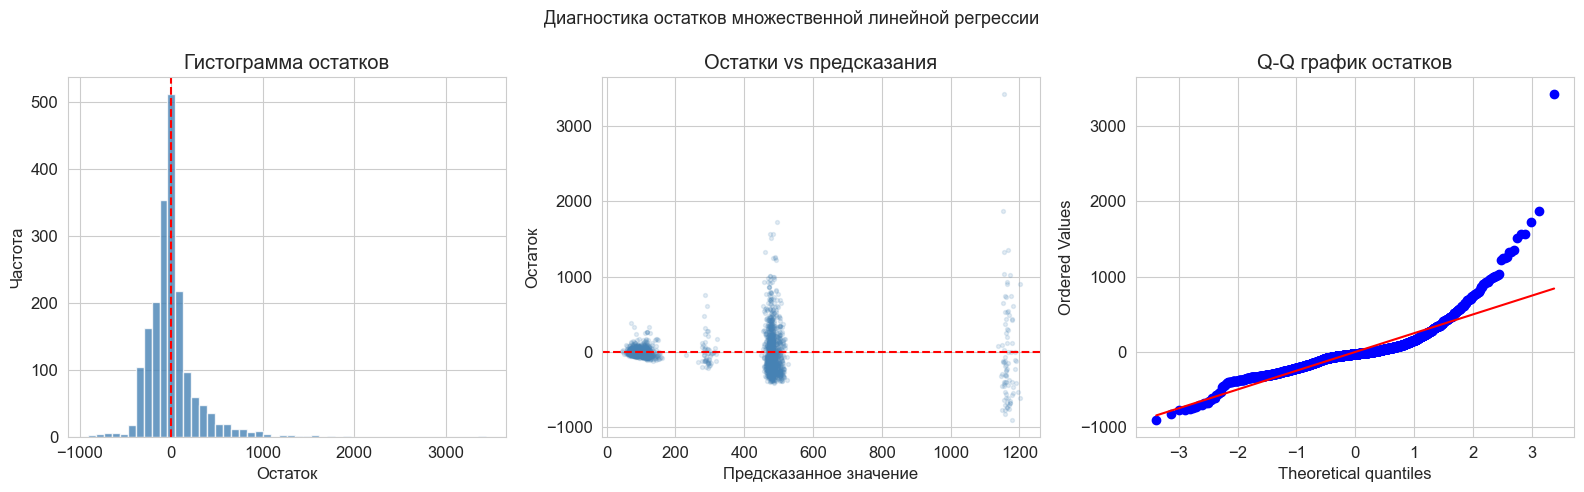


Тест Шапиро–Уилка (n=500): stat=0.8721, p=7.60e-20
Среднее остатков: -1.1400
Ст. откл. остатков: 274.65 мс

Вывод: p < 0.05 → гипотеза о нормальности остатков отвергается.
Виден паттерн гетероскедастичности: разброс растёт с предсказанным значением.


In [7]:
# Анализ остатков модели
residuals_test = y_test - y_mlr_pred

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Диагностика остатков множественной линейной регрессии', fontsize=13)

# Гистограмма остатков
axes[0].hist(residuals_test, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_xlabel('Остаток')
axes[0].set_ylabel('Частота')
axes[0].set_title('Гистограмма остатков')
axes[0].axvline(0, color='red', linewidth=1.5, linestyle='--')

# Остатки vs предсказания
axes[1].scatter(y_mlr_pred, residuals_test, alpha=0.15, s=8, color='steelblue')
axes[1].axhline(0, color='red', linewidth=1.5, linestyle='--')
axes[1].set_xlabel('Предсказанное значение')
axes[1].set_ylabel('Остаток')
axes[1].set_title('Остатки vs предсказания')

# Q-Q plot
stats.probplot(residuals_test, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q график остатков')

plt.tight_layout()
plt.show()

# Тест Шапиро–Уилка
sample_res = residuals_test[np.random.choice(len(residuals_test), 500, replace=False)]
stat_sw, p_sw = stats.shapiro(sample_res)
print(f'\nТест Шапиро–Уилка (n=500): stat={stat_sw:.4f}, p={p_sw:.2e}')
print(f'Среднее остатков: {residuals_test.mean():.4f}')
print(f'Ст. откл. остатков: {residuals_test.std():.2f} мс')
print('\nВывод: p < 0.05 → гипотеза о нормальности остатков отвергается.')
print('Виден паттерн гетероскедастичности: разброс растёт с предсказанным значением.')

---
## 4.3. Интерпретация коэффициентов и важность признаков

Коэффициент $\beta_j$ интерпретируется как: при увеличении признака $x_j$ на одну единицу (при прочих равных) ожидаемое время выполнения изменяется на $\beta_j$ мс.  
Для **стандартизованных** коэффициентов — изменение в стандартных отклонениях целевой переменной при изменении предиктора на 1 ст.откл.

Топ-10 признаков по стандартизованному коэффициенту:
            Признак  Коэф. (нестандарт.)  Стандарт. коэф.
  query_type_INSERT           -1072.0440          -1.0923
  query_type_SELECT            -683.1426          -0.9133
  query_type_UPDATE           -1043.6690          -0.9094
  query_type_DELETE           -1089.7004          -0.8220
    query_type_DROP            -871.3718          -0.3825
         cpu_x_conn             -12.0721          -0.0326
      country_China              31.7702           0.0260
       cpu_load_pct               8.0881           0.0219
country_Netherlands              23.4885           0.0173
       ram_usage_mb              -4.9776          -0.0134


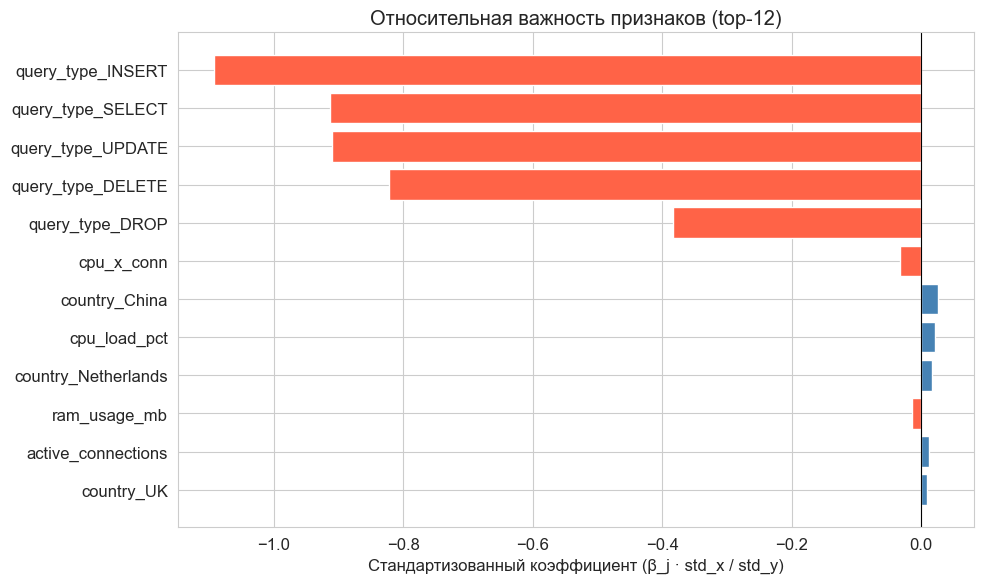


Интерпретация ключевых коэффициентов:
  query_type_INSERT: уменьшает время выполнения на 1072.04 мс при единичном изменении
  query_type_SELECT: уменьшает время выполнения на 683.14 мс при единичном изменении
  query_type_UPDATE: уменьшает время выполнения на 1043.67 мс при единичном изменении
  query_type_DELETE: уменьшает время выполнения на 1089.70 мс при единичном изменении
  query_type_DROP: уменьшает время выполнения на 871.37 мс при единичном изменении


In [8]:
# Стандартизованные коэффициенты для сравнения важности
std_y = y_train.std()
std_x = X_train.std(axis=0)
beta_std = mlr.coef_ * std_x / std_y

df_importance = pd.DataFrame({
    'Признак': feature_names,
    'Коэф. (нестандарт.)': mlr.coef_,
    'Стандарт. коэф.': beta_std
}).sort_values('Стандарт. коэф.', key=abs, ascending=False)

print('Топ-10 признаков по стандартизованному коэффициенту:')
print(df_importance.head(10).to_string(index=False, float_format='{:.4f}'.format))

fig, ax = plt.subplots(figsize=(10, 6))
top_imp = df_importance.head(12)
colors = ['tomato' if v < 0 else 'steelblue' for v in top_imp['Стандарт. коэф.'].values]
ax.barh(top_imp['Признак'].values[::-1], top_imp['Стандарт. коэф.'].values[::-1], color=colors[::-1])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Стандартизованный коэффициент (β_j · std_x / std_y)')
ax.set_title('Относительная важность признаков (top-12)')
plt.tight_layout()
plt.show()

print('\nИнтерпретация ключевых коэффициентов:')
for _, row in df_importance.head(5).iterrows():
    sign = 'увеличивает' if row['Коэф. (нестандарт.)'] > 0 else 'уменьшает'
    print(f'  {row["Признак"]}: {sign} время выполнения на {abs(row["Коэф. (нестандарт.)"]):.2f} мс при единичном изменении')

---
## 4.4. Построение нелинейной регрессии

### 4.4.1. Полиномиальная регрессия (степень 2)

$$\hat{y} = \beta_0 + \sum_{j=1}^p \beta_j x_j + \sum_{j=1}^p \sum_{k \geq j}^p \beta_{jk} x_j x_k$$

### 4.4.2. Лог-линейная регрессия

$$\log(\hat{y} + 1) = \beta_0 + \sum_{j=1}^p \beta_j x_j \quad \Rightarrow \quad \hat{y} = \exp(\hat{z}) - 1$$

Логарифмическое преобразование компенсирует правостороннюю асимметрию `execution_time_ms` и стабилизирует дисперсию остатков.

In [9]:
# Полиномиальная регрессия степени 2 по 4 базовым числовым признакам
# (на полном наборе признаков даёт взрыв размерности → переобучение)
base_num_idx = [feature_names.index(f) for f in
                ['cpu_load_pct', 'ram_usage_mb', 'active_connections', 'rows_affected']]
X_train_base = X_train[:, base_num_idx]
X_test_base  = X_test[:, base_num_idx]

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_base)
X_test_poly  = poly.transform(X_test_base)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)
y_poly_pred = poly_reg.predict(X_test_poly)

r2_poly  = r2_score(y_test, y_poly_pred)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_poly_pred))

print('Полиномиальная регрессия (степень 2) — метрики на тесте:')
print(f'  R²   = {r2_poly:.4f}')
print(f'  RMSE = {rmse_poly:.2f} мс')
if r2_poly < 0:
    print('  ⚠ R² < 0: модель хуже, чем предсказание средним → переобучение!')

Полиномиальная регрессия (степень 2) — метрики на тесте:
  R²   = -0.0244
  RMSE = 372.87 мс
  ⚠ R² < 0: модель хуже, чем предсказание средним → переобучение!


Лог-линейная регрессия — метрики:
  R² (log-шкала) = 0.6593
  R² (исх. шкала) = 0.4091
  RMSE            = 283.20 мс
  MAE             = 164.45 мс


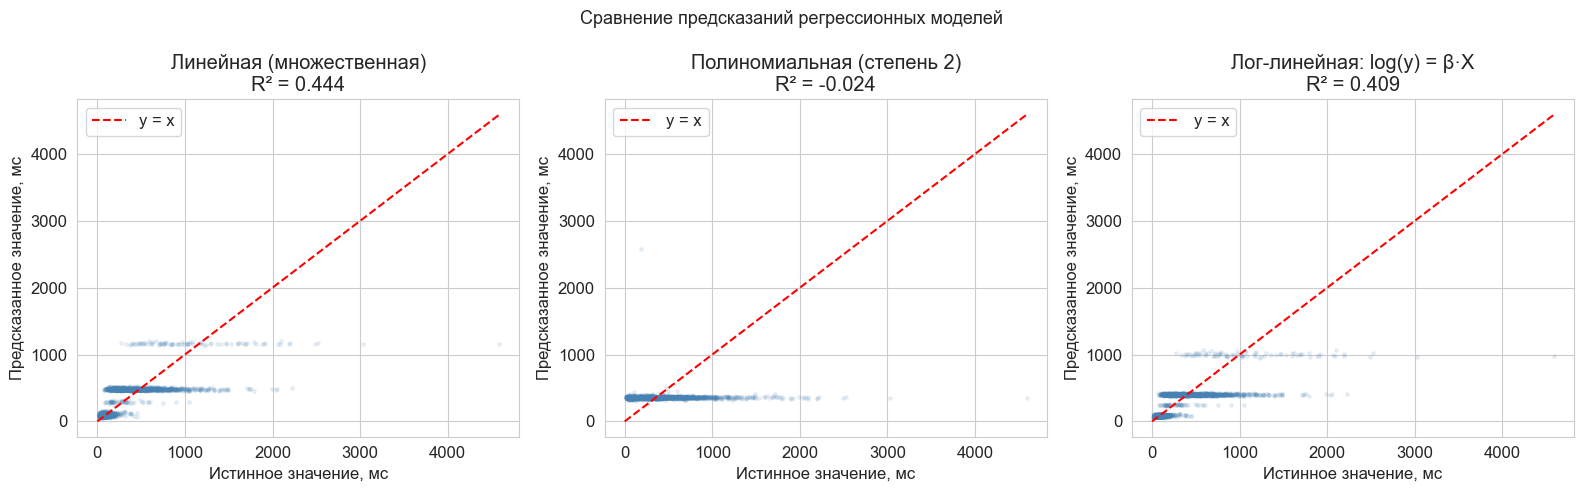

In [10]:
# Лог-линейная регрессия: log(y+1) = β·X
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)

log_reg = LinearRegression()
log_reg.fit(X_train, y_train_log)

# Качество на логарифмической шкале
y_log_pred_log = log_reg.predict(X_test)
r2_log_scale = r2_score(y_test_log, y_log_pred_log)

# Обратное преобразование для оценки на исходной шкале
y_log_pred = np.expm1(y_log_pred_log)
r2_log  = r2_score(y_test, y_log_pred)
rmse_log = np.sqrt(mean_squared_error(y_test, y_log_pred))
mae_log  = mean_absolute_error(y_test, y_log_pred)

print('Лог-линейная регрессия — метрики:')
print(f'  R² (log-шкала) = {r2_log_scale:.4f}')
print(f'  R² (исх. шкала) = {r2_log:.4f}')
print(f'  RMSE            = {rmse_log:.2f} мс')
print(f'  MAE             = {mae_log:.2f} мс')

# Сравнительный график наблюдаемые vs предсказания
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Сравнение предсказаний регрессионных моделей', fontsize=13)

def plot_pred_scatter(ax, y_true, y_pred, r2, title):
    ax.scatter(y_true, y_pred, alpha=0.1, s=6, color='steelblue')
    lim = max(y_true.max(), y_pred.max())
    ax.plot([0, lim], [0, lim], 'r--', linewidth=1.5, label='y = x')
    ax.set_xlabel('Истинное значение, мс')
    ax.set_ylabel('Предсказанное значение, мс')
    ax.set_title(f'{title}\nR² = {r2:.3f}')
    ax.legend()

plot_pred_scatter(axes[0], y_test, y_mlr_pred,  r2_mlr,  'Линейная (множественная)')
plot_pred_scatter(axes[1], y_test, y_poly_pred, r2_poly, 'Полиномиальная (степень 2)')
plot_pred_scatter(axes[2], y_test, y_log_pred,  r2_log,  'Лог-линейная: log(y) = β·X')
plt.tight_layout()
plt.show()

---
## 4.5. Использование различных метрик при идентификации моделей

| Метрика | Формула | Смысл |
|---|---|---|
| MSE | $\frac{1}{n}\sum (y_i - \hat{y}_i)^2$ | Средний квадрат ошибок; штрафует выбросы |
| RMSE | $\sqrt{\text{MSE}}$ | В единицах целевой переменной |
| MAE | $\frac{1}{n}\sum|y_i - \hat{y}_i|$ | Устойчив к выбросам |
| R² | $1 - \frac{\sum(y_i-\hat{y}_i)^2}{\sum(y_i-\bar{y})^2}$ | Доля объяснённой дисперсии |
| R²adj | $1 - (1-R^2)\frac{n-1}{n-p-1}$ | Штрафует за лишние предикторы |

Сводная таблица метрик регрессионных моделей:
                    Модель      MSE     RMSE      MAE      R²   R²adj
    Множественная линейная  75431.7 274.6483 171.6416  0.4442  0.4384
Полиномиальная (степень 2) 139033.7 372.8723 260.0235 -0.0244 -0.0319
              Лог-линейная  80200.3 283.1966 164.4493  0.4091  0.4029


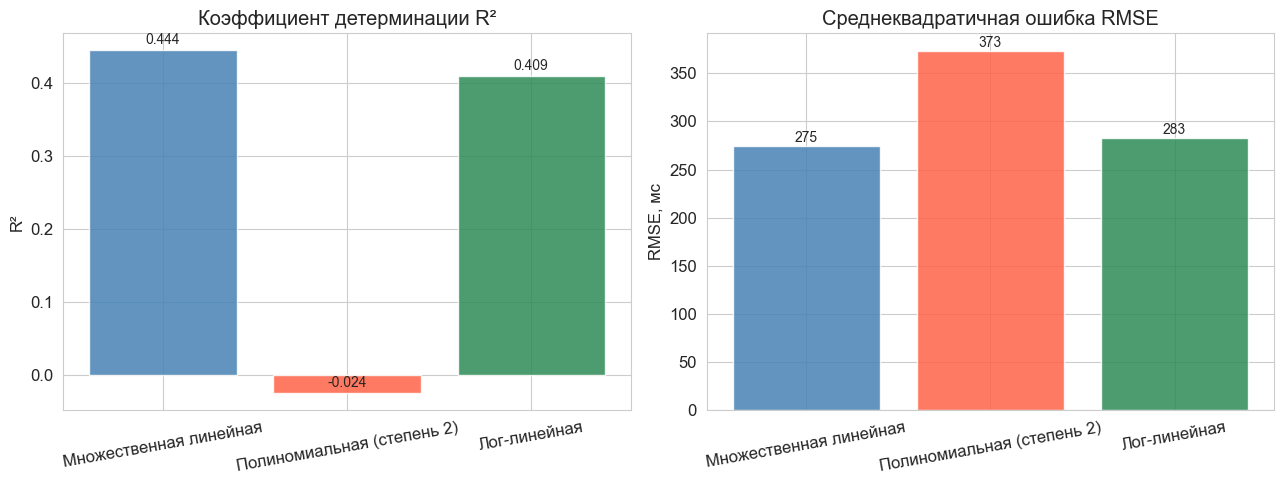

In [11]:
def regression_metrics(y_true, y_pred, n_features, label):
    n = len(y_true)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    r2a  = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    return {'Модель': label, 'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R²': r2, 'R²adj': r2a}

metrics_table = pd.DataFrame([
    regression_metrics(y_test, y_mlr_pred,  X_test.shape[1], 'Множественная линейная'),
    regression_metrics(y_test, y_poly_pred, X_test_poly.shape[1], 'Полиномиальная (степень 2)'),
    regression_metrics(y_test, y_log_pred,  X_test.shape[1], 'Лог-линейная'),
])

print('Сводная таблица метрик регрессионных моделей:')
print(metrics_table.to_string(index=False,
      float_format=lambda x: f'{x:.4f}' if abs(x) < 1000 else f'{x:.1f}'))

# Визуализация R² и RMSE
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = metrics_table['Модель']
x_pos = np.arange(len(models))
palette = ['steelblue', 'tomato', 'seagreen']

bars1 = axes[0].bar(x_pos, metrics_table['R²'], color=palette, alpha=0.85, edgecolor='white')
for bar, val in zip(bars1, metrics_table['R²']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{val:.3f}', ha='center', va='bottom', fontsize=10)
axes[0].set_xticks(x_pos); axes[0].set_xticklabels(models, rotation=10)
axes[0].set_ylabel('R²'); axes[0].set_title('Коэффициент детерминации R²')

bars2 = axes[1].bar(x_pos, metrics_table['RMSE'], color=palette, alpha=0.85, edgecolor='white')
for bar, val in zip(bars2, metrics_table['RMSE']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val:.0f}', ha='center', va='bottom', fontsize=10)
axes[1].set_xticks(x_pos); axes[1].set_xticklabels(models, rotation=10)
axes[1].set_ylabel('RMSE, мс'); axes[1].set_title('Среднеквадратичная ошибка RMSE')

plt.tight_layout()
plt.show()

---
## 4.6. Квантильная регрессия

Квантильная регрессия оценивает условные квантили отклика (а не среднее). Для квантиля $\tau \in (0,1)$ минимизируется **pinball loss**:

$$\rho_\tau(u) = u \cdot \tau \cdot \mathbb{1}[u \geq 0] + u \cdot (\tau - 1) \cdot \mathbb{1}[u < 0]$$

$$\hat{\boldsymbol{\beta}}_\tau = \arg\min_{\boldsymbol{\beta}} \sum_{i=1}^n \rho_\tau(y_i - \mathbf{x}_i^\top \boldsymbol{\beta})$$

- $\tau = 0.5$ — медианная регрессия (эквивалент L1)
- $\tau = 0.75$ — прогноз «потолка»; превышение = сигнал риска
- $\tau = 0.25$ — прогноз «пола»

In [12]:
quantiles = [0.25, 0.5, 0.75]
qr_models = {}
qr_preds  = {}

for q in quantiles:
    qr = QuantileRegressor(quantile=q, alpha=0.0, solver='highs')
    qr.fit(X_train, y_train)
    qr_models[q] = qr
    qr_preds[q]  = qr.predict(X_test)
    print(f'Квантильная регрессия τ={q}: интерсепт={qr.intercept_:.2f}')

# Покрытие: доля наблюдений ниже Q75
coverage_75 = (y_test <= qr_preds[0.75]).mean()
print(f'\nДоля тестовых наблюдений ниже Q75: {coverage_75:.3f} (ожидается ≈ 0.75)')

Квантильная регрессия τ=0.25: интерсепт=678.64
Квантильная регрессия τ=0.5: интерсепт=1017.79
Квантильная регрессия τ=0.75: интерсепт=1460.35

Доля тестовых наблюдений ниже Q75: 0.735 (ожидается ≈ 0.75)


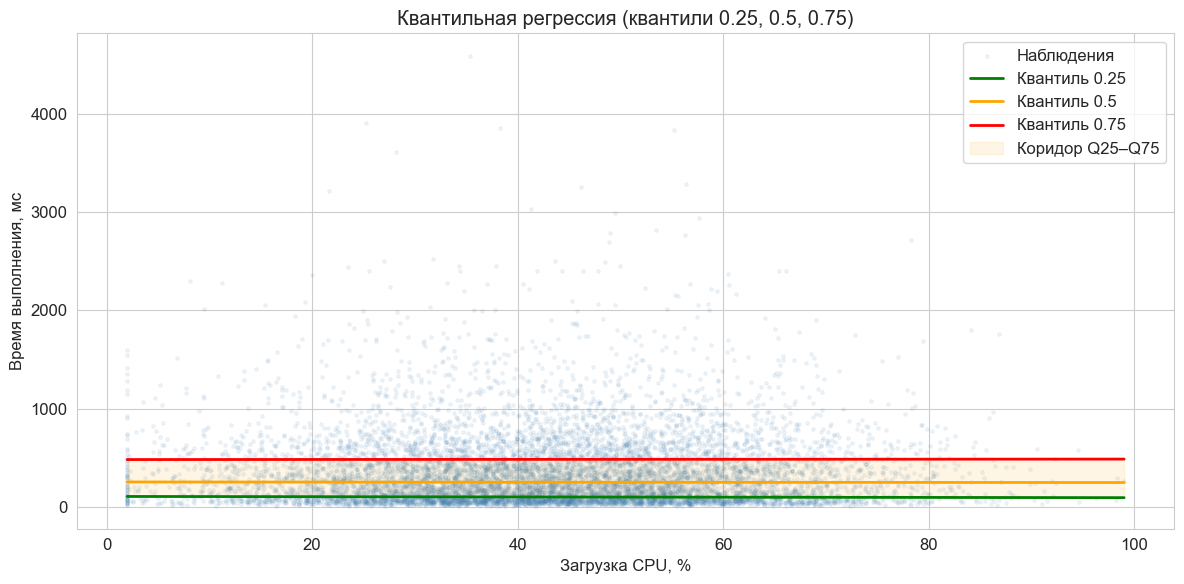

Вывод: коридор Q25–Q75 расширяется при росте CPU →
гетероскедастичность подтверждается квантильной регрессией.


In [13]:
# Визуализация квантильной регрессии: отображаем относительно cpu_load_pct
cpu_vals = df_reg['cpu_load_pct'].values

# Для наглядности строим одномерную квантильную регрессию по cpu_load_pct
qr1d_models = {}
qr1d_preds  = {}
x_1d_train = cpu_vals.reshape(-1, 1)
y_1d = df_reg['execution_time_ms'].values

for q in quantiles:
    qr1d = QuantileRegressor(quantile=q, alpha=0.0, solver='highs')
    qr1d.fit(x_1d_train, y_1d)
    qr1d_models[q] = qr1d
    qr1d_preds[q]  = qr1d.predict(x_1d_train)

sort_idx = np.argsort(cpu_vals)
x_sorted = cpu_vals[sort_idx]

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(cpu_vals, y_1d, alpha=0.08, s=6, color='steelblue', label='Наблюдения')
colors_q = {0.25: 'green', 0.5: 'orange', 0.75: 'red'}
for q in quantiles:
    ax.plot(x_sorted, qr1d_preds[q][sort_idx],
            linewidth=2, color=colors_q[q], label=f'Квантиль {q}')
ax.fill_between(x_sorted,
                qr1d_preds[0.25][sort_idx],
                qr1d_preds[0.75][sort_idx],
                alpha=0.1, color='orange', label='Коридор Q25–Q75')
ax.set_xlabel('Загрузка CPU, %')
ax.set_ylabel('Время выполнения, мс')
ax.set_title('Квантильная регрессия (квантили 0.25, 0.5, 0.75)')
ax.legend()
plt.tight_layout()
plt.show()

print('Вывод: коридор Q25–Q75 расширяется при росте CPU →')
print('гетероскедастичность подтверждается квантильной регрессией.')

In [14]:
# Сравнение квантильных моделей (на тесте) — pinball loss
def pinball_loss(y_true, y_pred, tau):
    u = y_true - y_pred
    return np.mean(np.where(u >= 0, tau * u, (tau - 1) * u))

print('Pinball loss на тестовой выборке:')
for q in quantiles:
    pb = pinball_loss(y_test, qr_preds[q], q)
    print(f'  τ={q}: {pb:.4f}')

# Различия между квантильными коэффициентами
print('\nКоэффициенты квантильных моделей (топ-6 признаков):')
top_feat_idx = np.argsort(np.abs(qr_models[0.5].coef_))[::-1][:6]
top_feat_names = [feature_names[i] for i in top_feat_idx]
df_qr_coef = pd.DataFrame(
    {f'τ={q}': qr_models[q].coef_[top_feat_idx] for q in quantiles},
    index=top_feat_names
)
print(df_qr_coef.to_string(float_format='{:.4f}'.format))

Pinball loss на тестовой выборке:
  τ=0.25: 54.5854
  τ=0.5: 82.1883
  τ=0.75: 78.8365

Коэффициенты квантильных моделей (топ-6 признаков):
                     τ=0.25     τ=0.5     τ=0.75
query_type_DELETE -644.9724 -946.8397 -1365.5272
query_type_INSERT -634.3205 -934.7458 -1340.9055
query_type_UPDATE -619.5955 -912.9266 -1307.4579
query_type_DROP   -522.8860 -752.2475 -1095.6484
query_type_SELECT -420.6636 -613.2767  -861.8992
country_India        4.4351  -11.8854     2.2418


---
## 4.7. Резюме: сравнение моделей и выбор метрик

In [15]:
# Итоговая сводная таблица
summary = pd.DataFrame([
    {'Модель': 'Простая линейная (cpu_load_pct)', 'R²': r2_slr, 'RMSE, мс': rmse_slr, 'Примечание': 'Один предиктор — недостаточен'},
    {'Модель': 'Множественная линейная',          'R²': r2_mlr, 'RMSE, мс': rmse_mlr, 'Примечание': 'Базовая модель'},
    {'Модель': 'Полиномиальная (степень 2)',       'R²': r2_poly, 'RMSE, мс': rmse_poly, 'Примечание': 'Переобучение'},
    {'Модель': 'Лог-линейная',                    'R²': r2_log,  'RMSE, мс': rmse_log,  'Примечание': 'Учитывает асимметрию'},
])
print('=== Итоговое сравнение моделей ===')
print(summary.to_string(index=False,
      float_format=lambda x: f'{x:.4f}' if isinstance(x, float) else str(x)))

print('\n=== Выводы ===')
print(f'1. Лучшая R² у множественной линейной регрессии: {r2_mlr:.4f} (RMSE={rmse_mlr:.1f} мс).')
print(f'2. Полиномиальная степень 2 даёт R²={r2_poly:.4f} — переобучение (отрицательное значение).')
print(f'3. Лог-линейная улучшает симметрию остатков, R²={r2_log:.4f} на исходной шкале.')
print('4. Квантильная регрессия выявила гетероскедастичность: коридор Q25–Q75 расширяется с CPU.')
print('5. Для мониторинга рекомендуется: множественная регрессия + Q75 как порог тревоги.')

=== Итоговое сравнение моделей ===
                         Модель      R²  RMSE, мс                    Примечание
Простая линейная (cpu_load_pct)  0.0000  371.2308 Один предиктор — недостаточен
         Множественная линейная  0.4442  274.6483                Базовая модель
     Полиномиальная (степень 2) -0.0244  372.8723                  Переобучение
                   Лог-линейная  0.4091  283.1966          Учитывает асимметрию

=== Выводы ===
1. Лучшая R² у множественной линейной регрессии: 0.4442 (RMSE=274.6 мс).
2. Полиномиальная степень 2 даёт R²=-0.0244 — переобучение (отрицательное значение).
3. Лог-линейная улучшает симметрию остатков, R²=0.4091 на исходной шкале.
4. Квантильная регрессия выявила гетероскедастичность: коридор Q25–Q75 расширяется с CPU.
5. Для мониторинга рекомендуется: множественная регрессия + Q75 как порог тревоги.


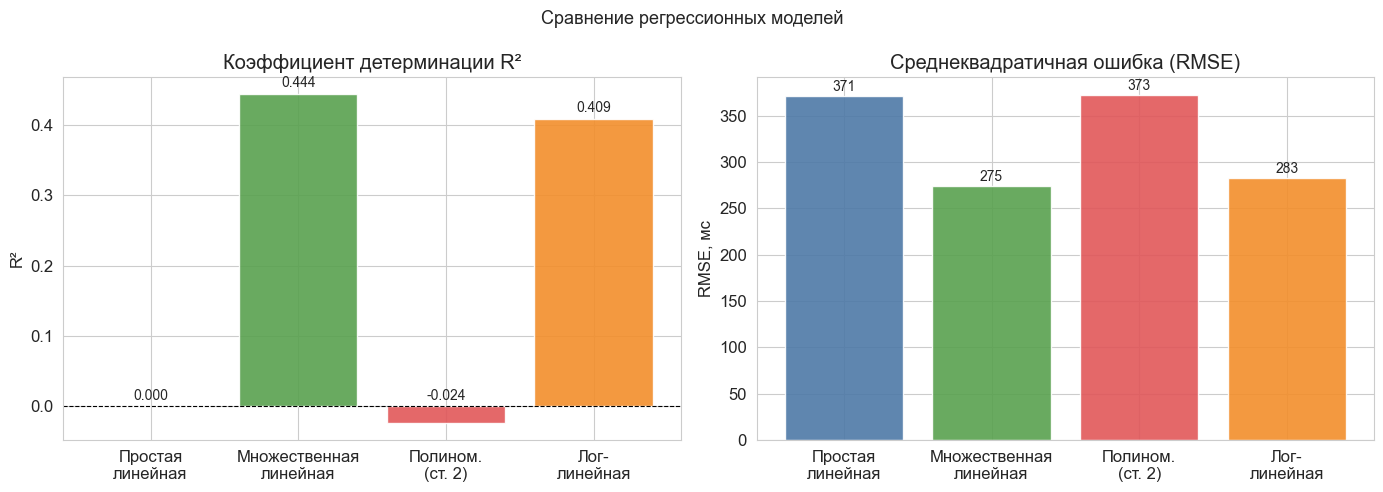

In [16]:
# Итоговая диаграмма: R² и RMSE всех моделей
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Сравнение регрессионных моделей', fontsize=13)

model_labels = ['Простая\nлинейная', 'Множественная\nлинейная', 'Полином.\n(ст. 2)', 'Лог-\nлинейная']
r2_vals   = [r2_slr,  r2_mlr,  r2_poly,  r2_log]
rmse_vals = [rmse_slr, rmse_mlr, rmse_poly, rmse_log]
palette4 = ['#4e79a7', '#59a14f', '#e15759', '#f28e2b']

bars = axes[0].bar(model_labels, r2_vals, color=palette4, alpha=0.9, edgecolor='white')
for bar, val in zip(bars, r2_vals):
    ypos = max(bar.get_height(), 0) + 0.005
    axes[0].text(bar.get_x() + bar.get_width()/2, ypos, f'{val:.3f}',
                 ha='center', va='bottom', fontsize=10)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_ylabel('R²')
axes[0].set_title('Коэффициент детерминации R²')

bars2 = axes[1].bar(model_labels, rmse_vals, color=palette4, alpha=0.9, edgecolor='white')
for bar, val in zip(bars2, rmse_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                 f'{val:.0f}', ha='center', va='bottom', fontsize=10)
axes[1].set_ylabel('RMSE, мс')
axes[1].set_title('Среднеквадратичная ошибка (RMSE)')

plt.tight_layout()
plt.show()